# Image restoration: deconvolution with field and colour dependent PSFs

Every camera lens blurs, and a phone lens blurs differently at every point
of the sensor and in every colour. If the point spread functions are known,
measured on a test bench or computed from the design and refined by phase
retrieval, part of that blur can be undone after the exposure. This
notebook surveys how, from the classical filters to what runs in phone
cameras today, and tries the methods on the five element f/1.8 phone lens
of notebook 159 (phone camera lens with Forbes Q polynomials).

The questions are practical ones. How much does the PSF change over the
field and between the colour channels, and how should a restoration handle
that? How much of the lost contrast can be won back at a realistic photon
count before the noise takes over? What happens when the PSF used for the
restoration is not quite the PSF of the camera? And what do the learned
methods add?

The tools come from the library: the ray traced PSFs of `raytrace.System`,
the FFTs of `fft`, the camera noise model `processing.CameraNoiser`
(photon and read noise as in notebook 148, detectors and photon statistics),
and the Bayer mosaic and demosaicing of `sensor` from
notebook 93 (the sensor). The new module `restoration` holds the channel PSFs, the
space variant blur model and the solvers.

## 0. The state of the art in brief

**The imaging model.** For a colour channel $c$ with spectral
sensitivity $s_c(\lambda)$ and a scene $x(\mathbf u, \lambda)$, the image is
$$y_c(\mathbf r) = M_c(\mathbf r) \int\!\!\int s_c(\lambda)\, h(\mathbf r, \mathbf u; \lambda)\, x(\mathbf u, \lambda)\, d\mathbf u\, d\lambda + n,$$
with the PSF $h$ integrated over the pixel, the colour filter mosaic $M_c$
and photon plus read noise $n$. With a scene of constant colour locally,
the wavelength integral collapses into one polychromatic *channel PSF*
$h_c(\mathbf r, \mathbf u)$. Restoration means solving this linear inverse
problem for $x$. It is ill posed: the MTF falls to small values well below
the Nyquist frequency, and whatever the lens did not transmit, no algorithm
recovers without prior knowledge.

**Classical, shift invariant.** The inverse filter divides by the OTF and
amplifies the noise without bound. The *Wiener* filter (Wiener 1949) is the
minimum mean square error linear estimate,
$X = H^* Y/(|H|^2 + S_n/S_x)$; with a constant noise to signal ratio it is
Tikhonov regularization, with the scene spectrum $S_x \propto f^{-2 \ldots 3}$ of
natural images it is the real Wiener filter. *Richardson–Lucy*
(Richardson 1972, Lucy 1974) is the expectation maximization algorithm for
Poisson data (Shepp and Vardi 1982): multiplicative, positive, flux
conserving, regularized only by stopping early. Edge preserving priors came
with *total variation* (Rudin, Osher and Fatemi 1992) and the sparse
gradient priors of natural images (Levin et al. 2007; the hyper-Laplacian of
Krishnan and Fergus 2009), solved by half-quadratic splitting (Geman and
Yang 1995), ADMM (Boyd et al. 2011) or primal-dual methods (Chambolle and
Pock 2011; Condat 2013, Vu 2013). These are the workhorses to this day,
and they are what the learned methods unroll.

**Field dependence.** A lens is not isoplanatic. Three families of
methods: (i) *piecewise constant*: cut the image into overlapping tiles,
deconvolve each with its own PSF and blend; the "efficient filter flow" of
Hirsch et al. (2010) puts this into one consistent linear operator.
(ii) *Interpolated PSFs*: the PSF at each pixel is interpolated between
measured nodes, which makes the blur a sum of a few convolutions of weighted
images (Nagy and O'Leary 1998). (iii) *Low rank*: an SVD of the PSFs over
the field gives "eigen-PSFs" with smooth weight maps (Flicker and Rigaut
2005, from adaptive optics; reviewed with error bounds by Denis et al. 2015).
Both (ii) and (iii) give a fast forward operator and its adjoint, so that
every iterative solver works unchanged. For consumer lenses, Kee et al.
(2011) calibrated field dependent PSFs with a chart and a parametric model,
Schuler et al. (2011, 2012) corrected non-stationary aberrations of real
lenses non-blind and blind, and Heide et al. (2013) made single element
lenses usable with per channel, field dependent PSFs. PSFs are measured
with point sources or edges (Joshi et al. 2008), with noise targets that
contain all frequencies (Mosleh et al. 2015, Delbracio et al. 2012), or
computed from the lens design; a design PSF is typically refined by fitting
a few aberration coefficients to measurements.

**Colour.** The channels have different PSFs (axial colour) and different
image positions (lateral colour). Phone and camera ISPs correct lateral
colour as a per channel *warp* of R and B to G, which is cheap and exact
for the shift. Deconvolving each channel with its own PSF also removes the
shift, but each channel alone is noisy and may have zeros in its OTF
where another has none. The *cross-channel prior* of Heide et al. (2013)
couples them: the edges of R and B should lie where those of G are,
in proportion to the intensities, $|\nabla x_c\, x_g - \nabla x_g\, x_c|_1$.
On raw Bayer data, demosaicing first correlates the noise and creates its
own artefacts; *joint* demosaicing and deconvolution solves the inverse
problem on the mosaic directly (FlexISP, Heide et al. 2014).

**Learned and unrolled.** Non-blind deep deconvolution started with
networks that clean up a Wiener estimate (Schuler et al. 2013; Xu et al.
2014). Plug-and-play methods keep the physics and replace the prior by a
learned denoiser inside half-quadratic splitting (IRCNN, Zhang et al. 2017;
DPIR, Zhang et al. 2021); *unrolled* (deep unfolding) networks fix the
number of iterations and learn their parameters end to end (USRNet, Zhang
et al. 2020); the deep Wiener deconvolution network of Dong et al. (2020)
does the Wiener step in feature space. For spatially varying blur,
MultiWienerNet (Yanny et al. 2022) applies a Wiener filter per calibrated
PSF and lets a CNN fuse the results, 625 to 1600 times faster than
iterative space variant solvers. For lens aberrations specifically, Chen
et al. (2021) train a field adaptive network on images simulated from the
lens prescription and the sensor (shown on a phone camera); Li et al.
(2021) feed calibrated PSF maps to a network that alternates patch wise
deconvolution with a learned prior and adapts to a new lens in minutes;
Gong et al. (2024) build the low rank PSF model into a network for blind
correction. The current frontier (2025–26) is *universal* and blind
correction: networks pre-trained on large libraries of simulated lenses,
with a learned codebook of PSF priors, that adapt to a new lens zero or few
shot (Qian et al. 2025, arXiv:2511.17126), and one step diffusion models
that add the veiling glare of real lenses (Qian et al. 2026,
arXiv:2610.00318) or restore metalens images (Weligampola et al. 2025).
End-to-end design goes one step further and optimizes the lens and the
network together (Sitzmann et al. 2018; Tseng et al. 2021).
The common thread: the *forward model with measured or designed PSFs* is
what all of them are trained or conditioned on, and that is the part this
notebook builds.

**What phone ISPs actually do.** Manufacturers publish little, but the
documented building blocks are clear. The Android camera API exposes the
per frame stages a vendor ISP implements: lens shading correction
(`SHADING_MODE`), lateral chromatic aberration correction
(`COLOR_CORRECTION_ABERRATION_MODE`), geometric distortion correction
(`DISTORTION_CORRECTION_MODE`, with the lens distortion model in
`LENS_DISTORTION`), noise reduction (`NOISE_REDUCTION_MODE`) and edge
enhancement (`EDGE_MODE`). The last is classically a tuned, field
dependent sharpening (unsharp masking with gains per region and per
brightness), a cheap approximation of a regularized inverse filter,
not a full deconvolution. Multi-frame merging does more for noise and
resolution than any single frame deconvolution: HDR+ merges a burst
(Hasinoff et al. 2016) and handheld multi-frame super-resolution uses
the natural hand tremor to fill the Bayer gaps (Wronski et al. 2019). For
blur, Google's Polyblur (Delbracio et al. 2021) estimates a mild blur
from the image and inverts it with a polynomial of the blur, fast enough
for 12 Mpixel in a fraction of a second on a phone; it is blind and not
field specific. Learned processing on the neural accelerator (denoising,
detail enhancement, super-resolution) has largely replaced hand tuned
sharpening in flagship phones, but the details are proprietary; a
review is Delbracio et al. (2021), "Mobile computational photography: a
tour".

## 1. The lens, the sensor and the channels

The lens of notebook 159 (phone camera lens with Forbes Q polynomials):
f = 4 mm, f/1.8, image height 3 mm, imaged onto a 4:3 sensor with 1 µm
pixels, the pitch of current 50 Mpixel phone main cameras. The
diffraction cut-off is above the sampling frequency, as in every phone
camera: the pixels, not the lens, set the Nyquist limit, and there is no
optical low pass filter. White is set to 1000 photo electrons per pixel,
an indoor exposure for a 1 µm pixel (full wells are a few thousand).

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from pyoptics import phone_lens as pl
from pyoptics import restoration as rs
from pyoptics import sensor as se
from pyoptics import colour
from pyoptics.processing import CameraNoiser

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.grid": True, "grid.color": "0.88", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
CH, CCOL = ("R", "G", "B"), (RED, GREEN, BLUE)
t_start = time.time()

lens = pl.phone_lens()
PITCH = 1.0e-3                       # pixel pitch (mm)
H = pl.IMAGE_HEIGHT                  # half diagonal of the sensor (mm)
SX, SY = 0.8*H, 0.6*H                # half width and half height of the 4:3 sensor
WL_NM = np.arange(430, 671, 20)      # wavelengths of the spectral sum (nm)
WL = WL_NM*1e-6
NP = 31                              # PSF size in pixels
PEAK, READ = 1000.0, 2.0             # photo electrons at white, read noise (e- rms)
print("f = {:.2f} mm, f/{:.2f}, sensor {:.1f} x {:.1f} mm, {:.0f} x {:.0f} pixels of {:.1f} µm ({:.0f} Mpixel)".format(
    pl.EFL, pl.F_NUMBER, 2*SX, 2*SY, 2*SX/PITCH, 2*SY/PITCH, PITCH*1e3, 4*SX*SY/PITCH**2/1e6))
print("diffraction cut-off at 550 nm: {:.0f} lp/mm = {:.2f} cycles per pixel; Nyquist {:.0f} lp/mm".format(
    1/(550e-6*pl.F_NUMBER), PITCH/(550e-6*pl.F_NUMBER), se.nyquist(PITCH)))

f = 4.00 mm, f/1.80, sensor 4.8 x 3.6 mm, 4800 x 3600 pixels of 1.0 µm (17 Mpixel)
diffraction cut-off at 550 nm: 1010 lp/mm = 1.01 cycles per pixel; Nyquist 500 lp/mm


The channel PSFs are spectral sums. The lens is designed at the F, d and C
lines, but a colour channel integrates over a band of about 100 nm. The
PSFs are traced at 13 wavelengths from 430 to 670 nm and weighted with
model sensitivities of the three pixel types (`rs.cfa_sensitivity()`:
dye filters, silicon, IR cut filter at 650 nm; a model of the general
shape, not of a particular sensor):

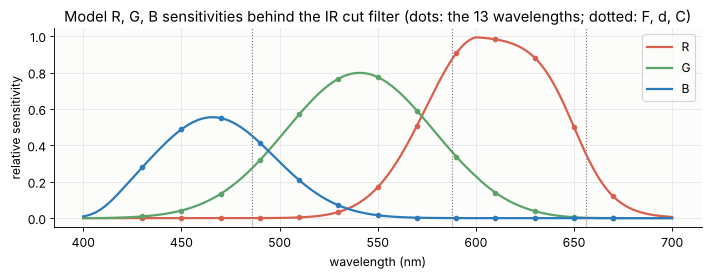

In [2]:
lam = np.linspace(400, 700, 301)
S = rs.cfa_sensitivity(lam)
fig, ax = plt.subplots(figsize=(9, 3.6))
for c in range(3):
    ax.plot(lam, S[c], color=CCOL[c], lw=2, label=CH[c])
    ax.plot(WL_NM, rs.cfa_sensitivity(WL_NM)[c], "o", color=CCOL[c], ms=4)
for w in pl.WAVELENGTHS:
    ax.axvline(w*1e6, color=GREY, ls=":", lw=1)
ax.set_xlabel("wavelength (nm)")
ax.set_ylabel("relative sensitivity")
ax.set_title("Model R, G, B sensitivities behind the IR cut filter (dots: the 13 wavelengths; dotted: F, d, C)")
ax.legend()
fig.tight_layout()

## 2. The PSFs over the field

`rs.psf_samples()` finds the field angle whose green (550 nm) chief ray
lands on a given sensor point (`rs.field_for_image_point()`, distortion
included), computes the PSF of every wavelength with `System.psf()` on a
grid four times finer than the pixels, shifts it by the chief ray offset of
that wavelength (lateral colour becomes part of the PSF), integrates over
the pixels and normalizes. `rs.channel_psfs()` forms the channel PSFs.
The six points lie on the sensor diagonal:

78 monochromatic PSFs in 28 s


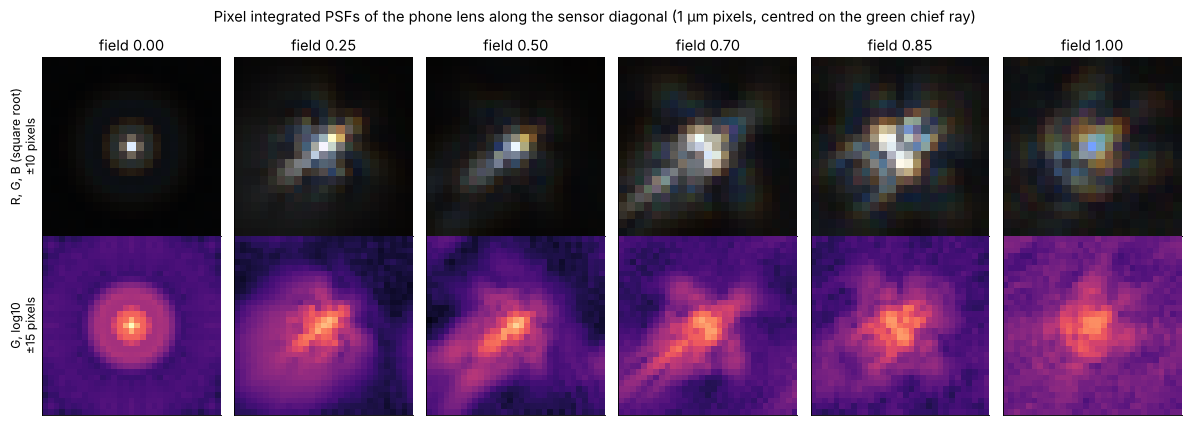

In [3]:
FR = np.array([0.0, 0.25, 0.5, 0.7, 0.85, 1.0])
diag = np.column_stack([FR*SX, FR*SY])                        # points on the sensor diagonal
t0 = time.time()
mono, shifts = rs.psf_samples(lens, diag, WL, PITCH, n_pix=NP)
psf_diag = rs.channel_psfs(mono, WL_NM)                       # (field, channel, NP, NP)
print("{} monochromatic PSFs in {:.0f} s".format(mono.shape[0]*mono.shape[1], time.time() - t0))


def to_rgb(p, gamma=0.5):
    """Channel PSFs (3, n, n) as an RGB picture, all scaled by the largest value."""
    return (np.clip(p/p.max(), 0, 1)**gamma).transpose(1, 2, 0)


c = NP//2
z = 10
fig, axes = plt.subplots(2, len(FR), figsize=(15, 5.4))
for k, f in enumerate(FR):
    axes[0, k].imshow(to_rgb(psf_diag[k][:, c - z:c + z + 1, c - z:c + z + 1]), origin="lower",
                      extent=[-z - .5, z + .5, -z - .5, z + .5])
    axes[0, k].set_title("field {:.2f}".format(f))
    axes[1, k].imshow(np.log10(psf_diag[k, 1] + 1e-6), origin="lower", cmap="magma", vmin=-5, vmax=-0.5,
                      extent=[-c - .5, c + .5, -c - .5, c + .5])
    for a in axes[:, k]:
        a.grid(False)
        a.set_xticks([]); a.set_yticks([])
axes[0, 0].set_ylabel("R, G, B (square root)\n±10 pixels")
axes[1, 0].set_ylabel("G, log10\n±15 pixels")
fig.suptitle("Pixel integrated PSFs of the phone lens along the sensor diagonal (1 µm pixels, centred on the green chief ray)")
fig.tight_layout()

On the axis the lens is close to diffraction limited: half of the light
falls within 1 µm of the centre, 80 % within 3–5 µm, and the MTF at half
the Nyquist frequency (250 lp/mm) is 0.34 to 0.41. Off axis the PSF grows
a streak along the diagonal, longest around 0.5 to 0.7 field, and a
diffuse halo. From 0.25 to 0.85 field 80 % of the light lies within
5–7 µm, at the corner within 10 µm. The MTF depends strongly on the
direction: at 0.7 field it is 0.12–0.14 radially and close to zero
tangentially at 250 lp/mm, at 0.25 field the other way round. A
restoration has to know the direction of the blur, not only its size.

The three channels have almost the same size everywhere: the lens is well
corrected for colour, and what differs between them is the structure. The
chief rays of 430 and 670 nm land up to 2 µm apart at the corner, but the
centroids of the channel PSFs differ by less than 0.4 µm. Each channel
averages over its band, and the IR cut filter trims the red. Within a
channel, the lateral colour shows up as a coloured smear of the PSF
rather than as a shift.

The PSFs are centred on the green chief ray, so the restored image is
still distorted. The distortion of this lens reaches 4.35 % at 0.82 field
and turns back to 2.5 % at the corner
(notebook 159, phone camera lens with Forbes Q polynomials). Correcting it is a separate geometric warp
after the restoration, as in an ISP, and is the subject of notebook
[161 (distortion, lateral colour and lens shading correction)](161_distortion_shading_correction.ipynb).

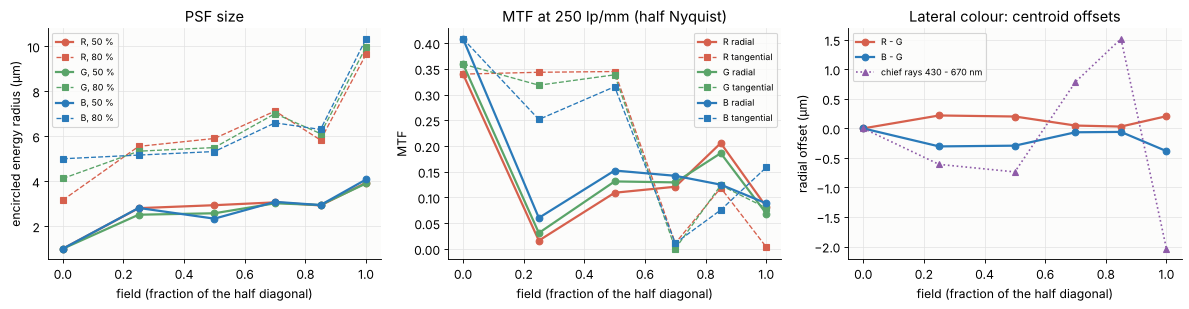

In [4]:
def mtf_at(p, f, direction):
    """|OTF| of a pixel PSF at f cycles per pixel along a unit direction (x, y)."""
    yy, xx = np.indices(p.shape) - p.shape[0]//2
    return np.abs(np.sum(p*np.exp(-2j*np.pi*f*(direction[0]*xx + direction[1]*yy))))


def centroid(p):
    yy, xx = np.indices(p.shape) - p.shape[0]//2
    return np.array([np.sum(p*xx), np.sum(p*yy)])/p.sum()


radial = np.array([0.8, 0.6])
tangential = np.array([-0.6, 0.8])
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ch in range(3):
    axes[0].plot(FR, [rs.encircled_energy_radius(psf_diag[k, ch], 0.5, PITCH*1e3) for k in range(len(FR))],
                 "o-", color=CCOL[ch], lw=2, label=CH[ch] + ", 50 %")
    axes[0].plot(FR, [rs.encircled_energy_radius(psf_diag[k, ch], 0.8, PITCH*1e3) for k in range(len(FR))],
                 "s--", color=CCOL[ch], lw=1.2, label=CH[ch] + ", 80 %")
    axes[1].plot(FR, [mtf_at(psf_diag[k, ch], 0.25, radial) for k in range(len(FR))], "o-", color=CCOL[ch],
                 lw=2, label=CH[ch] + " radial")
    axes[1].plot(FR, [mtf_at(psf_diag[k, ch], 0.25, tangential) for k in range(len(FR))], "s--",
                 color=CCOL[ch], lw=1.2, label=CH[ch] + " tangential")
    if ch != 1:
        axes[2].plot(FR, [(centroid(psf_diag[k, ch]) - centroid(psf_diag[k, 1])) @ radial*PITCH*1e3
                          for k in range(len(FR))], "o-", color=CCOL[ch], lw=2, label=CH[ch] + " - G")
axes[2].plot(FR, (shifts[:, 0] - shifts[:, -1]) @ radial*1e3, "^:", color=PURPLE, lw=1.5,
             label="chief rays 430 - 670 nm")
axes[0].set_ylabel("encircled energy radius (µm)")
axes[0].set_title("PSF size")
axes[1].set_ylabel("MTF")
axes[1].set_title("MTF at 250 lp/mm (half Nyquist)")
axes[2].set_ylabel("radial offset (µm)")
axes[2].set_title("Lateral colour: centroid offsets")
for a in axes:
    a.set_xlabel("field (fraction of the half diagonal)")
    a.legend(fontsize=8)
fig.tight_layout()

Two shortcuts are common and worth checking: using one design wavelength
per channel instead of the spectral sum, and ignoring that the channel PSF
depends on the light (a warm 3000 K lamp shifts the weight within each
band towards the red):

In [5]:
mono3, _ = rs.psf_samples(lens, diag, pl.WAVELENGTHS, PITCH, n_pix=NP)
design_line = mono3[:, ::-1]              # R <- 656 nm, G <- 587 nm, B <- 486 nm
warm = rs.channel_psfs(mono, WL_NM, spectrum=colour.planck(WL_NM, 3000.0))
cool = rs.channel_psfs(mono, WL_NM, spectrum=colour.planck(WL_NM, 6500.0))


def rel(a, b):
    return np.linalg.norm(a - b)/np.linalg.norm(b)


print("relative difference to the spectrally summed channel PSF (flat spectrum), R / G / B")
print("field   one design line per channel      3000 K black body          6500 K black body")
for k, f in enumerate(FR):
    print("{:5.2f}   ".format(f) + "  ".join("{:6.3f}".format(rel(design_line[k, ch], psf_diag[k, ch])) for ch in range(3))
          + "     " + "  ".join("{:6.3f}".format(rel(warm[k, ch], psf_diag[k, ch])) for ch in range(3))
          + "     " + "  ".join("{:6.3f}".format(rel(cool[k, ch], psf_diag[k, ch])) for ch in range(3)))

relative difference to the spectrally summed channel PSF (flat spectrum), R / G / B
field   one design line per channel      3000 K black body          6500 K black body
 0.00    0.084   0.106   0.036      0.007   0.020   0.021      0.003   0.004   0.001
 0.25    0.099   0.165   0.119      0.009   0.032   0.046      0.004   0.007   0.002
 0.50    0.092   0.152   0.134      0.009   0.035   0.052      0.004   0.007   0.003
 0.70    0.117   0.129   0.092      0.009   0.022   0.031      0.004   0.005   0.002
 0.85    0.144   0.156   0.129      0.011   0.028   0.037      0.005   0.006   0.002
 1.00    0.315   0.364   0.232      0.026   0.069   0.077      0.011   0.014   0.004


Using one design wavelength per channel gives a channel PSF that is
4–11 % off on the axis and 9–36 % off in the field, so the spectral sum
matters. The colour of the light matters less but not nothing: a 3000 K
lamp changes the G and B PSFs by up to 8 %, while daylight (6500 K) stays
within 2 % of a flat spectrum. A camera that restores with stored PSFs
can switch them with the white balance, which the ISP estimates anyway
for its colour correction matrices.

## 3. Noise

The noise sets how much can be restored. `CameraNoiser("camera")` draws
Poisson photo electrons and adds Gaussian read noise (the EMVA 1288 model of
notebook 93, the sensor, and the statistics of
notebook 148, detectors and photon statistics). At 1000 e- for white the shot noise dominates above a
few electrons; mid grey has an SNR of about 22.

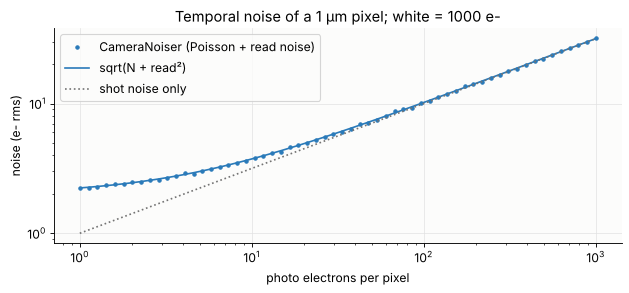

In [6]:
signal = np.logspace(0, np.log10(PEAK), 60)
cam = CameraNoiser("camera", read_noise=READ, rng=1)
emp = [np.std(cam(np.full((64, 64), s))) for s in signal]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.loglog(signal, emp, ".", color=BLUE, label="CameraNoiser (Poisson + read noise)")
ax.loglog(signal, np.sqrt(signal + READ**2), color=BLUE, lw=1.5, label="sqrt(N + read²)")
ax.loglog(signal, np.sqrt(signal), ":", color=GREY, label="shot noise only")
ax.set_xlabel("photo electrons per pixel")
ax.set_ylabel("noise (e- rms)")
ax.set_title("Temporal noise of a 1 µm pixel; white = {:.0f} e-".format(PEAK))
ax.legend()
fig.tight_layout()


def expose(blurred, rng):
    """Noisy image (relative to white = 1) of a blurred image (relative units)."""
    return CameraNoiser("camera", read_noise=READ, rng=rng)(np.clip(blurred, 0, None)*PEAK)/PEAK

## 4. Classical deconvolution on one field patch

First the shift invariant case: a patch of 256 × 256 pixels around the
0.7 field point, small enough that one PSF holds (section 5 checks how
small that has to be), green channel only. The scene is a dead leaves
texture (`rs.dead_leaves()`): occluding discs with a $1/r^3$ distribution of
radii, scale invariant with the $f^{-2}$ to $f^{-3}$ power spectrum of
natural images, and the target of the ISO 19567-2 texture tests for
phone cameras. The scene extends 24 pixels beyond the image on every side,
so that the boundary is unknown to the restoration, as in a real crop.

In [7]:
K07 = 3                                              # the 0.7 field point
psf07 = psf_diag[K07, 1]
N1, M1 = 256, 24
grey = rs.dead_leaves((N1 + 2*M1, N1 + 2*M1), r_min=1.5, r_max=100, rng=7)
truth1 = grey[M1:-M1, M1:-M1]
op07 = rs.SpaceVariantBlur.invariant(psf07, (N1, N1), margin=M1)
blur1 = op07.forward(grey)
y1 = expose(blur1, 8)
B = 16                                               # border left out of the PSNR
print("blurred {:.2f} dB, blurred and noisy {:.2f} dB".format(rs.psnr(blur1, truth1, border=B),
                                                           rs.psnr(y1, truth1, border=B)))

blurred 18.71 dB, blurred and noisy 18.54 dB


The Wiener filter needs the noise to signal ratio as a function of
frequency. The noise is white with a variance known from the photon count;
the scene spectrum is fitted as a power law (from the scene itself here; in
practice a typical natural image exponent is used):

In [8]:
F2 = np.abs(np.fft.rfft2(truth1 - truth1.mean()))**2/truth1.size
fy, fx = np.fft.fftfreq(N1)[:, None], np.fft.rfftfreq(N1)[None, :]
fr = np.hypot(fx, fy)
sel = (fr > 0.02) & (fr < 0.45)
slope, icpt = np.polyfit(np.log(fr[sel]), np.log(F2[sel]), 1)
noise_var = (np.mean(y1)*PEAK + READ**2)/PEAK**2       # per pixel, relative units
nsr_model = lambda f: noise_var/(np.exp(icpt)*np.maximum(f, 0.5/N1)**slope)
print("scene power spectrum ~ f^{:.2f}; noise variance {:.2e} (relative to white = 1)".format(slope, noise_var))

scene power spectrum ~ f^-2.93; noise variance 5.14e-04 (relative to white = 1)


Each method has one regularization parameter: the NSR of the Wiener filter,
the number of Richardson–Lucy iterations, the weight λ of the total
variation.

best: Wiener NSR 3.2e-02: 21.68 dB; spectral Wiener 22.59 dB; RL 28 iterations: 22.28 dB; TV λ = 1.8e-03: 23.54 dB


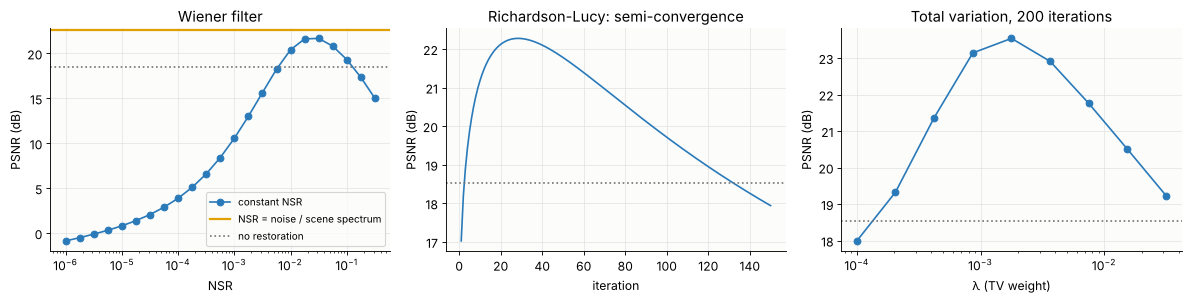

In [9]:
nsrs = np.logspace(-6, -0.5, 23)
p_wien = [rs.psnr(rs.wiener(y1, psf07, k), truth1, border=B) for k in nsrs]
x_wien_model = rs.wiener(y1, psf07, nsr_model)
p_wien_model = rs.psnr(x_wien_model, truth1, border=B)
bg = READ**2/PEAK
op07c = rs.SpaceVariantBlur.invariant(psf07, (N1, N1), margin=M1)
p_rl, rl_store = [], {}
rs.richardson_lucy(y1 + bg, op07c, 150, background=bg, callback=lambda i, x: (
    p_rl.append(rs.psnr(x[M1:-M1, M1:-M1], truth1, border=B)), rl_store.__setitem__(i + 1, x[M1:-M1, M1:-M1])))
lams = np.logspace(-4, -1.5, 9)
tv_store = {l: rs.deconvolve_tv(y1, op07c, l, n_iter=200)[M1:-M1, M1:-M1] for l in lams}
p_tv = [rs.psnr(tv_store[l], truth1, border=B) for l in lams]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
axes[0].semilogx(nsrs, p_wien, "o-", color=BLUE, label="constant NSR")
axes[0].axhline(p_wien_model, color=ORANGE, lw=2, label="NSR = noise / scene spectrum")
axes[0].set_xlabel("NSR")
axes[0].set_title("Wiener filter")
axes[1].plot(np.arange(1, len(p_rl) + 1), p_rl, color=BLUE)
axes[1].set_xlabel("iteration")
axes[1].set_title("Richardson-Lucy: semi-convergence")
axes[2].semilogx(lams, p_tv, "o-", color=BLUE)
axes[2].set_xlabel("λ (TV weight)")
axes[2].set_title("Total variation, 200 iterations")
for a in axes:
    a.axhline(rs.psnr(y1, truth1, border=B), color=GREY, ls=":", label="no restoration")
    a.set_ylabel("PSNR (dB)")
axes[0].legend(fontsize=9)
fig.tight_layout()
best = {"Wiener (constant NSR)": rs.wiener(y1, psf07, nsrs[np.argmax(p_wien)]),
        "Wiener (spectral NSR)": x_wien_model,
        "Richardson-Lucy": rl_store[int(np.argmax(p_rl)) + 1],
        "TV": tv_store[lams[np.argmax(p_tv)]]}
print("best: Wiener NSR {:.1e}: {:.2f} dB; spectral Wiener {:.2f} dB; RL {} iterations: {:.2f} dB; TV λ = {:.1e}: {:.2f} dB".format(
    nsrs[np.argmax(p_wien)], max(p_wien), p_wien_model, np.argmax(p_rl) + 1, max(p_rl), lams[np.argmax(p_tv)], max(p_tv)))

All three methods show the same trade-off: too little regularization
amplifies the noise, and too much leaves the blur. The best values, from
18.5 dB for the data:

- **Wiener with a constant NSR** (best NSR 0.032): 21.7 dB. With the
  *spectral* NSR, noise variance over the power law scene spectrum and
  nothing tuned, 22.6 dB: the frequency dependence is worth more than any
  choice of a constant.
- **Richardson–Lucy** peaks at 22.3 dB after 28 iterations and then
  slowly gets worse, because it starts to fit the noise; after 130
  iterations it is below the data. This semi-convergence makes the
  iteration count the regularization parameter, and it depends on the
  noise level.
- **TV** (λ = 0.0018): 23.5 dB, the best of the three.

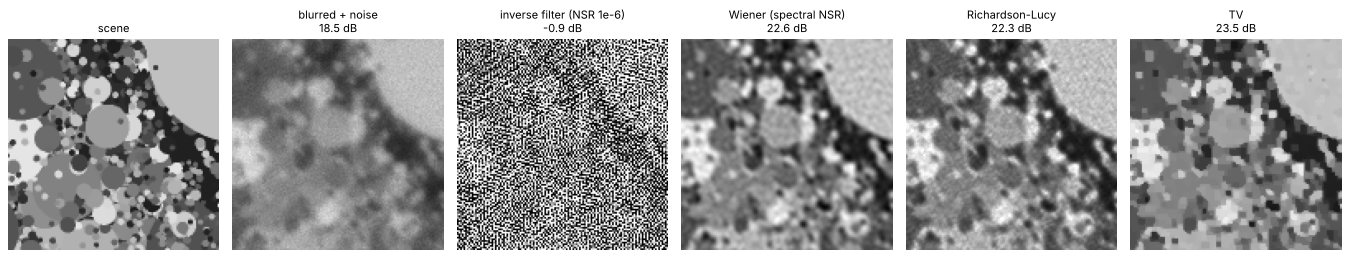

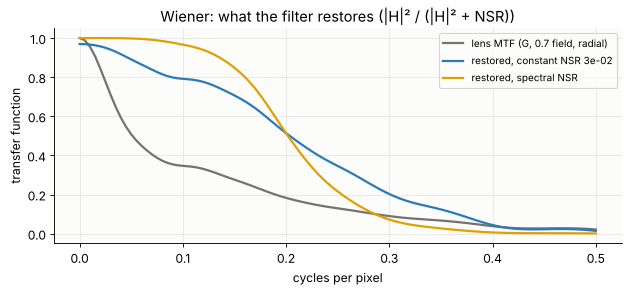

In [10]:
fig, axes = plt.subplots(1, 6, figsize=(17, 3.3))
sl = np.s_[60:188, 60:188]
for a, (name, img) in zip(axes, [("scene", truth1), ("blurred + noise", y1), ("inverse filter (NSR 1e-6)",
                                  rs.wiener(y1, psf07, 1e-6))] + list(best.items())[1:]):
    a.imshow(img[sl], cmap="gray", vmin=0, vmax=1, origin="lower")
    a.set_title(name if name == "scene" else "{}\n{:.1f} dB".format(name, rs.psnr(img, truth1, border=B)), fontsize=10)
    a.axis("off")
fig.tight_layout()

# effective transfer functions along the radial direction
f = np.linspace(0, 0.5, 101)
Hm = np.array([mtf_at(psf07, q, radial) for q in f])
Hc = np.array([np.sum(psf07*np.exp(-2j*np.pi*q*(radial[0]*(np.indices(psf07.shape)[1] - NP//2)
                                                + radial[1]*(np.indices(psf07.shape)[0] - NP//2)))) for q in f])
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(f, Hm, color=GREY, lw=2, label="lens MTF (G, 0.7 field, radial)")
for name, k, col in (("constant NSR {:.0e}".format(nsrs[np.argmax(p_wien)]), nsrs[np.argmax(p_wien)], BLUE),
                     ("spectral NSR", nsr_model(f), ORANGE)):
    ax.plot(f, np.abs(Hc)**2/(np.abs(Hc)**2 + k), color=col, lw=2, label="restored, " + name)
ax.set_xlabel("cycles per pixel")
ax.set_ylabel("transfer function")
ax.set_title("Wiener: what the filter restores (|H|² / (|H|² + NSR))")
ax.legend(fontsize=9)
fig.tight_layout()

The inverse filter (NSR $10^{-6}$) shows why regularization is
indispensable. Wiener is smooth, Richardson–Lucy grainy, and TV
piecewise flat. TV is at its best on a dead leaves scene, which *is*
piecewise flat; on natural textures it gives the "watercolour" look that
led to hyper-Laplacian and then learned priors.

The transfer function plot shows what the Wiener filter does. With the
spectral NSR, the restored transfer function is close to 1 up to
0.1 cycles per pixel (100 lp/mm). It lets go above about 0.2, where the
lens MTF is below 0.2 and the noise wins. The constant NSR restores less
at low frequencies and more noise at high ones. Nothing above about
0.35 cycles per pixel comes back at this photon count: the limit is the
SNR, not the algorithm.

## 5. Field dependence: the corner of the image

Now the difficult part of the image: a crop of 512 × 512 pixels at the
sensor corner, from 0.76 field to the edge. The PSFs are computed on
a 5 × 5 grid of nodes, every 128 pixels.

In [11]:
NC, MC = 512, 24
nodes = np.linspace(0, NC - 1, 5)
x0, y0 = SX - NC*PITCH, SY - NC*PITCH                 # lower left corner of the crop on the sensor
grid_pts = np.array([(x0 + (j + 0.5)*PITCH, y0 + (i + 0.5)*PITCH) for i in nodes for j in nodes])
t0 = time.time()
mono_c, _ = rs.psf_samples(lens, grid_pts, WL, PITCH, n_pix=NP)
psf_c = rs.channel_psfs(mono_c, WL_NM).reshape(5, 5, 3, NP, NP)
print("{} PSFs in {:.0f} s; crop from field {:.2f} to {:.2f}".format(
    mono_c.shape[0]*mono_c.shape[1], time.time() - t0, np.hypot(x0, y0)/H, 1.0))

325 PSFs in 153 s; crop from field 0.76 to 1.00


How fast the PSF changes, and how few eigen-PSFs describe it:

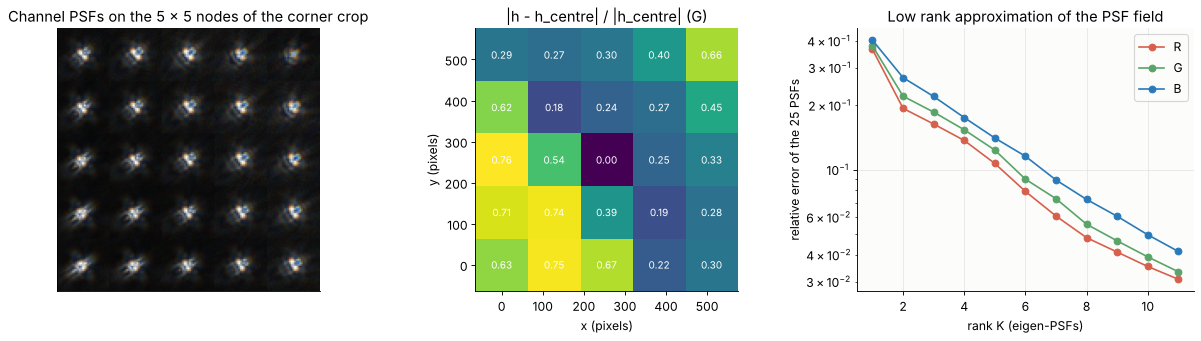

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
mosaic_img = np.zeros((5*NP, 5*NP, 3))
for i in range(5):
    for j in range(5):
        mosaic_img[i*NP:(i + 1)*NP, j*NP:(j + 1)*NP] = to_rgb(psf_c[i, j])
axes[0].imshow(mosaic_img, origin="lower")
axes[0].set_title("Channel PSFs on the 5 x 5 nodes of the corner crop")
axes[0].grid(False); axes[0].set_xticks([]); axes[0].set_yticks([])
dist = np.array([[rel(psf_c[i, j, 1], psf_c[2, 2, 1]) for j in range(5)] for i in range(5)])
im = axes[1].imshow(dist, origin="lower", cmap="viridis", extent=[-64, NC + 64, -64, NC + 64])
for i in range(5):
    for j in range(5):
        axes[1].text(nodes[j], nodes[i], "{:.2f}".format(dist[i, j]), ha="center", va="center", color="w", fontsize=9)
axes[1].set_title("|h - h_centre| / |h_centre| (G)")
axes[1].set_xlabel("x (pixels)"); axes[1].set_ylabel("y (pixels)")
axes[1].grid(False)
for ch in range(3):
    P = psf_c[:, :, ch].reshape(25, NP*NP)
    s = np.linalg.svd(P, compute_uv=False)
    err = [np.sqrt(np.sum(s[k:]**2)/np.sum(s**2)) for k in range(1, 12)]
    axes[2].semilogy(range(1, 12), err, "o-", color=CCOL[ch], label=CH[ch])
axes[2].set_xlabel("rank K (eigen-PSFs)")
axes[2].set_ylabel("relative error of the 25 PSFs")
axes[2].set_title("Low rank approximation of the PSF field")
axes[2].legend()
fig.tight_layout()

Neighbouring nodes, 128 pixels apart, differ by 18–54 % of the norm of
the PSF, and nodes 256 pixels apart by up to 76 %: the PSF is far from
isoplanatic even over 100 pixels. The inner nodes (about 0.8 field) carry
the diagonal streak, the outer ones are rounder and more diffuse. The
eigen-PSFs converge well: four of them leave 14–18 % error in the 25 PSFs
and ten 3–5 %.

The simulation blurs a colour dead leaves scene with two Siemens stars
(one near the inner corner of the crop, one at the sensor corner) with the
PSFs of all 5 × 5 nodes, interpolated between them. The restoration gets
only every second node (3 × 3, every 256 pixels), so that the model used
for the restoration is not the model that made the data (the "inverse
crime" of testing a method with its own model would flatter it).

In [13]:
rng = np.random.default_rng(11)
cols = lambda g, n: np.clip(g.uniform(0.05, 0.9, (n, 1))*g.uniform(0.5, 1.5, (n, 3)), 0, 1)
sceneC = rs.dead_leaves((NC + 2*MC, NC + 2*MC), r_min=1.5, r_max=150, colours=cols, rng=12)
star = rs.siemens_star(120, spokes=40)
yy, xx = np.indices(star.shape) - 60
disc = np.hypot(yy, xx) < 58
for cy, cx in ((MC + 90, MC + 90), (MC + NC - 90, MC + NC - 90)):
    win = sceneC[:, cy - 60:cy + 60, cx - 60:cx + 60]
    win[:, disc] = star[disc]
truthC = sceneC[:, MC:-MC, MC:-MC]
true_ops = [rs.SpaceVariantBlur.from_grid(psf_c[:, :, ch], nodes, nodes, (NC, NC), margin=MC) for ch in range(3)]
blurC = np.array([true_ops[ch].forward(sceneC[ch]) for ch in range(3)])
yC = np.array([expose(blurC[ch], 20 + ch) for ch in range(3)])
nd = nodes[::2]                                    # restoration uses only the 3 x 3 nodes
psf_c3 = psf_c[::2, ::2]
print("restoration nodes every {:.0f} pixels; data PSNR {:.2f} dB".format(nd[1] - nd[0], rs.psnr(yC, truthC, border=B)))

restoration nodes every 256 pixels; data PSNR 15.30 dB


Five restorations: the Wiener filter with the PSF of the axis (what a
restoration that ignores the field does), with the PSF of the crop centre
(one PSF per tile), the Wiener filter of every node blended with the
bilinear weights of the nodes (`rs.blended_deconvolve()`), and the two
iterative solvers on space variant models: Richardson–Lucy on the 9
interpolated node PSFs (it needs a blur that is positive everywhere, which
eigen-PSFs with their negative lobes are not), and TV
(`rs.deconvolve_tv()`, Condat–Vu primal-dual) on the rank 4 model
(`rs.SpaceVariantBlur.from_grid(..., rank=4)`), with less than half the
convolutions:

In [14]:
methods, times = {}, {}


def run(name, fn):
    t = time.time()
    methods[name] = np.array([fn(ch) for ch in range(3)])
    times[name] = time.time() - t


nsr_c = lambda ch: (lambda f: (np.mean(yC[ch])*PEAK + READ**2)/PEAK**2/(np.exp(icpt)*np.maximum(f, 0.5/N1)**slope))
run("Wiener, PSF of the axis", lambda ch: rs.wiener(yC[ch], psf_diag[0, ch], nsr_c(ch)))
run("Wiener, PSF of the crop centre", lambda ch: rs.wiener(yC[ch], psf_c[2, 2, ch], nsr_c(ch)))
run("Wiener, blended over 3 x 3 nodes", lambda ch: rs.blended_deconvolve(
    yC[ch], psf_c3[:, :, ch], nd, nd, lambda w, p: rs.wiener(w, p, nsr_c(ch))))
lowrank = [rs.SpaceVariantBlur.from_grid(psf_c3[:, :, ch], nd, nd, (NC, NC), rank=4, margin=MC) for ch in range(3)]
interp = [rs.SpaceVariantBlur.from_grid(psf_c3[:, :, ch], nd, nd, (NC, NC), margin=MC) for ch in range(3)]
run("Richardson-Lucy, 9 PSFs, 40 it.", lambda ch: rs.richardson_lucy(
    yC[ch] + bg, interp[ch], 40, background=bg)[MC:-MC, MC:-MC])
run("RL, all 25 PSFs (the data's model)", lambda ch: rs.richardson_lucy(
    yC[ch] + bg, true_ops[ch], 40, background=bg)[MC:-MC, MC:-MC])
LAM_TV = lams[np.argmax(p_tv)]
tvC = [None]*3


def tv_channel(ch):
    tvC[ch] = rs.deconvolve_tv(yC[ch], lowrank[ch], LAM_TV, n_iter=200)
    return tvC[ch][MC:-MC, MC:-MC]


run("TV, rank 4", tv_channel)
print("method                                  R       G       B      all   (PSNR, dB)   time")
print("{:38s} ".format("blurred + noise") + " ".join("{:7.2f}".format(rs.psnr(yC[ch], truthC[ch], border=B))
                                                   for ch in range(3)) + " {:7.2f}".format(rs.psnr(yC, truthC, border=B)))
for name, img in methods.items():
    print("{:38s} ".format(name) + " ".join("{:7.2f}".format(rs.psnr(img[ch], truthC[ch], border=B)) for ch in range(3))
          + " {:7.2f}   {:6.1f} s".format(rs.psnr(img, truthC, border=B), times[name]))

method                                  R       G       B      all   (PSNR, dB)   time
blurred + noise                          15.25   15.17   15.47   15.30
Wiener, PSF of the axis                  15.97   16.06   16.55   16.18      0.1 s
Wiener, PSF of the crop centre           17.93   17.75   17.73   17.80      0.0 s
Wiener, blended over 3 x 3 nodes         18.90   18.68   18.90   18.83      0.2 s
Richardson-Lucy, 9 PSFs, 40 it.          18.83   18.61   18.73   18.72     10.5 s
RL, all 25 PSFs (the data's model)       18.95   18.73   18.85   18.84     30.9 s
TV, rank 4                               19.53   19.34   19.45   19.44     27.2 s


From 15.3 dB for the data:

- **One PSF from the axis** gains little (16.2 dB). Its PSF is smaller
  than the real one, so it under-restores, which at least does no harm.
- **One PSF from the crop centre** gains 2.5 dB (17.8 dB), but unevenly,
  as the maps below show.
- **Blended Wiener** over 3 × 3 nodes: 18.8 dB.
- **Richardson–Lucy on the 9 interpolated PSFs**: 18.7 dB in 11 s.
- **TV on the rank 4 eigen-PSF model**: 19.4 dB in 27 s, the best.
- **Richardson–Lucy with all 25 PSFs** that made the data: 18.8 dB. This
  is a model that a real camera does not have; that it gains only
  0.1 dB over the 3 × 3 nodes shows that, for this lens, nodes every
  256 pixels are dense enough in the corner.

Where in the crop the gains are, in blocks of 64 × 64 pixels:

Text(0, 0.5, 'y (pixels); the sensor corner is top right')

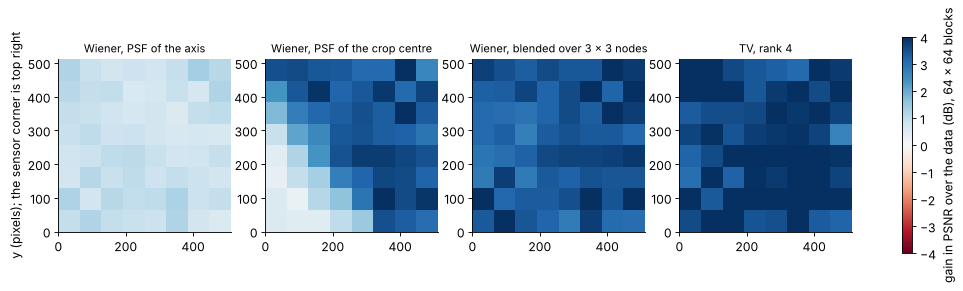

In [15]:
def local_psnr(img, ref, b=64):
    n = ref.shape[-1]//b
    return np.array([[rs.psnr(img[..., i*b:(i + 1)*b, j*b:(j + 1)*b], ref[..., i*b:(i + 1)*b, j*b:(j + 1)*b])
                      for j in range(n)] for i in range(n)])


show = ["Wiener, PSF of the axis", "Wiener, PSF of the crop centre", "Wiener, blended over 3 x 3 nodes", "TV, rank 4"]
base = local_psnr(yC, truthC)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.9))
for a, name in zip(axes, show):
    im = a.imshow(local_psnr(methods[name], truthC) - base, origin="lower", cmap="RdBu", vmin=-4, vmax=4,
                  extent=[0, NC, 0, NC])
    a.set_title(name, fontsize=10)
    a.grid(False)
fig.colorbar(im, ax=axes, label="gain in PSNR over the data (dB), 64 x 64 blocks", shrink=0.9)
axes[0].set_ylabel("y (pixels); the sensor corner is top right")

The crop centre PSF helps near the centre and the outer corner, but
hardly at all in the inner (lower left) part, where the PSF has the long
diagonal streak that the centre PSF lacks. The blended Wiener filter and
TV on the space variant model gain everywhere, TV by 3 to 4 dB.

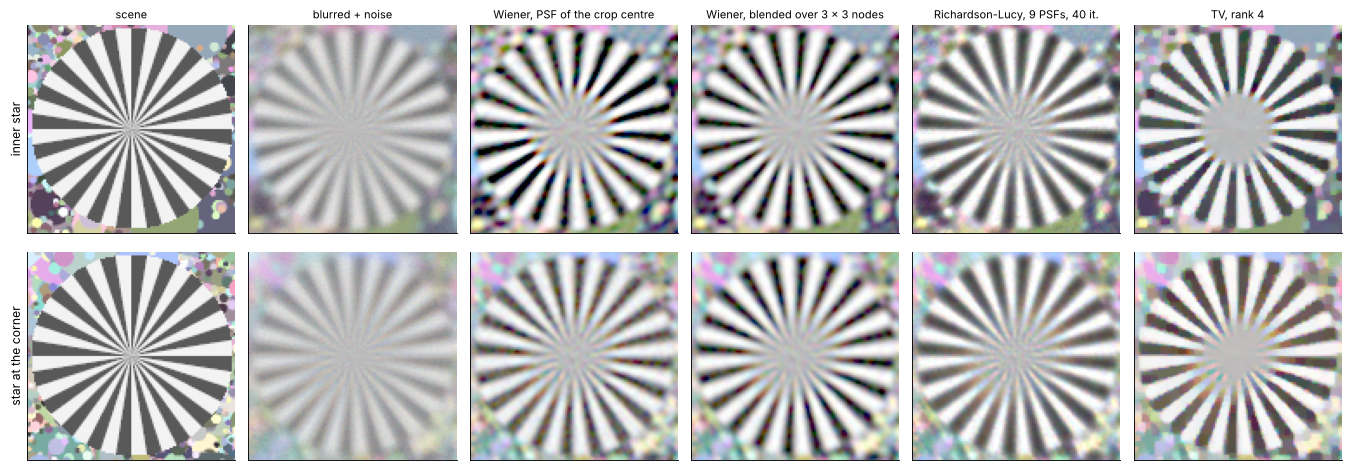

In [16]:
def srgb(img):
    return colour.srgb_gamma(np.clip(img, 0, 1)).transpose(1, 2, 0)


zooms = [("inner star", np.s_[:, 30:150, 30:150]), ("star at the corner", np.s_[:, NC - 150:NC - 30, NC - 150:NC - 30])]
cols_show = [("scene", truthC), ("blurred + noise", yC)] + [(n, methods[n]) for n in
                                                         ("Wiener, PSF of the crop centre", "Wiener, blended over 3 x 3 nodes",
                                                          "Richardson-Lucy, 9 PSFs, 40 it.", "TV, rank 4")]
fig, axes = plt.subplots(2, len(cols_show), figsize=(17, 6.2))
for r, (zn, sl) in enumerate(zooms):
    for k, (name, img) in enumerate(cols_show):
        axes[r, k].imshow(srgb(img[sl]), origin="lower")
        axes[r, k].set_xticks([]); axes[r, k].set_yticks([]); axes[r, k].grid(False)
        if r == 0:
            axes[r, k].set_title(name, fontsize=10)
    axes[r, 0].set_ylabel(zn)
fig.tight_layout()

At the inner star, the crop centre PSF gives high contrast but coloured
false detail towards the centre: it sharpens with the wrong kernel.
Richardson–Lucy and TV bring the spokes back closer to the centre with
less colour. At the corner star the differences are smaller; TV gives the
cleanest spokes, and no method recovers the innermost ones, because
those frequencies are lost.

## 6. Colour: channels, lateral colour and the Bayer mosaic

So far each channel was measured at every pixel, as with three sensors.
A phone sensor has a Bayer mosaic: every pixel sees one colour, green on
half of them, red and blue on a quarter each. Two ways to restore:

- demosaic first (`se.demosaic_malvar()`, notebook 93, the sensor), then
  deconvolve each channel as above;
- solve on the mosaic directly: the data term only counts the pixels of
  the channel (`mask=`), green first, then red and blue, with or without
  the cross-channel prior that ties their edges to the restored green.

The chroma error is the rms error of the chromaticities $r/(r+g+b)$ and
$b/(r+g+b)$ on the brighter half of the scene, a measure of colour fringes.

In [17]:
mask = se.bayer_masks((NC, NC))
raw = expose(se.mosaic(blurC), 30)
demo = se.demosaic_malvar(raw)
colour_res = {"full RGB data, TV per channel": methods["TV, rank 4"]}
t = time.time()
colour_res["Bayer: demosaic, then TV per channel"] = np.array(
    [rs.deconvolve_tv(demo[ch], lowrank[ch], LAM_TV, n_iter=200)[MC:-MC, MC:-MC] for ch in range(3)])
t_demo = time.time() - t
t = time.time()
g_raw = rs.deconvolve_tv(raw, lowrank[1], LAM_TV, n_iter=300, mask=mask[1])
joint = {}
for name, cross in (("Bayer: joint, TV per channel", 0.0), ("Bayer: joint, TV + cross-channel", 3*LAM_TV)):
    joint[name] = np.array([g_raw[MC:-MC, MC:-MC] if ch == 1 else rs.deconvolve_tv(
        raw, lowrank[ch], LAM_TV*(0.5 if cross else 1.0), n_iter=300, mask=mask[ch], reference=g_raw,
        cross=cross)[MC:-MC, MC:-MC] for ch in range(3)])
colour_res.update(joint)
t_joint = time.time() - t


def chroma_error(img, ref):
    """rms error of the chromaticity r/(r+g+b), b/(r+g+b) where the scene is not dark."""
    img = np.clip(img, 0, None)
    s, sr = img.sum(0), ref.sum(0)
    ok = sr > 0.3
    return np.sqrt(np.mean(((img[0]/np.maximum(s, 1e-3) - ref[0]/sr)**2 + (img[2]/np.maximum(s, 1e-3) - ref[2]/sr)**2)[ok]))


print("                                              PSNR R/G/B (dB)           all    chroma error")
print("{:44s}".format("Bayer: demosaic only (Malvar)") + " ".join("{:7.2f}".format(rs.psnr(demo[ch], truthC[ch], border=B))
                                                         for ch in range(3)) + " {:7.2f}   {:.4f}".format(
    rs.psnr(demo, truthC, border=B), chroma_error(demo[:, B:-B, B:-B], truthC[:, B:-B, B:-B])))
for name, img in colour_res.items():
    print("{:44s}".format(name) + " ".join("{:7.2f}".format(rs.psnr(img[ch], truthC[ch], border=B)) for ch in range(3))
          + " {:7.2f}   {:.4f}".format(rs.psnr(img, truthC, border=B), chroma_error(img[:, B:-B, B:-B], truthC[:, B:-B, B:-B])))
print("time: demosaic + TV {:.0f} s, joint (G, then R and B twice) {:.0f} s".format(t_demo, t_joint))

                                              PSNR R/G/B (dB)           all    chroma error
Bayer: demosaic only (Malvar)                 15.30   15.22   15.46   15.33   0.0674
full RGB data, TV per channel                 19.53   19.34   19.45   19.44   0.0645
Bayer: demosaic, then TV per channel          18.69   19.07   18.73   18.83   0.0769
Bayer: joint, TV per channel                  17.70   18.44   17.83   17.98   0.0666
Bayer: joint, TV + cross-channel              17.92   18.44   18.08   18.14   0.0615
time: demosaic + TV 24 s, joint (G, then R and B twice) 63 s


In PSNR, three full RGB channels give 19.4 dB. On the Bayer mosaic,
demosaicing first and then deconvolving gives 18.8 dB, and the joint
solution on the mosaic 18.0 dB, or 18.1 dB with the cross-channel prior.
Malvar's demosaicing already uses the gradients of green to fill red and
blue, which is a cross-channel prior of its own, and the joint solver has
only a quarter of the R and B samples to work with.

The chroma error tells a different story. Demosaicing alone has 0.067.
Deconvolving every channel on its own after demosaicing raises it to
0.077: the noise of each channel is amplified independently and turns
into coloured mottle, the "chroma noise" of over-sharpened phone
pictures. The joint solution on the mosaic stays at 0.067, and the
cross-channel prior lowers it to 0.062, below the unrestored image. This
is why ISPs sharpen mostly the luminance and denoise the chroma
separately and more strongly.

The cross-channel prior is weak here because the three channel PSFs are
nearly equal. It was made for lenses whose channels blur very
differently, such as the single element lenses of Heide et al., where
the sharpest channel carries the detail of the others.

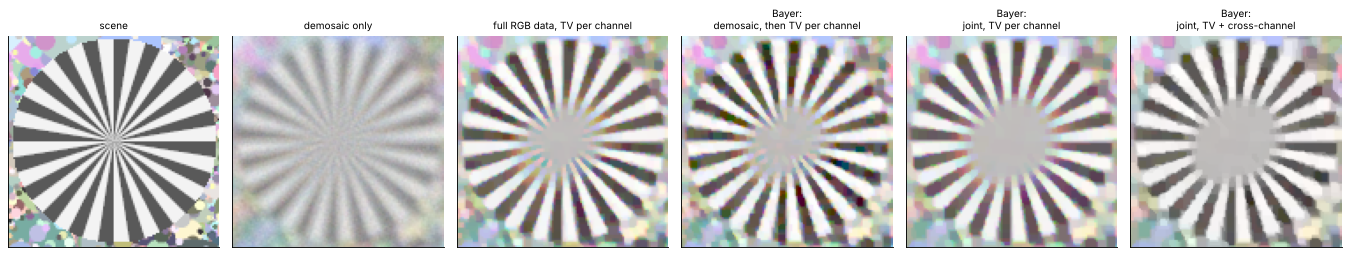

In [18]:
sl = np.s_[:, NC - 150:NC - 30, NC - 150:NC - 30]
show_c = [("scene", truthC), ("demosaic only", demo)] + list(colour_res.items())
fig, axes = plt.subplots(1, len(show_c), figsize=(17, 3.4))
for a, (name, img) in zip(axes, show_c):
    a.imshow(srgb(img[sl]), origin="lower")
    a.set_title(name.replace(": ", ":\n"), fontsize=9)
    a.set_xticks([]); a.set_yticks([]); a.grid(False)
fig.tight_layout()

At the corner star, the per channel restoration after demosaicing shows
coloured fringes on the grey spokes. The joint and cross-channel versions
are greyer, at the price of less recovered detail: the grey disc in the
centre, where the spokes are lost, is larger.

## 7. When the PSF is wrong

The PSF used for a restoration is never exactly the PSF of the camera. A
phone module focuses with a voice coil motor, the lens shifts with
temperature and the PSF changes with the object distance (notebook 159, phone camera lens with Forbes Q polynomials,
looked at 100 mm). Here the
data of the 0.7 field patch are made with the sensor shifted by up to
10 µm, the depth of focus being about $\pm 2 \lambda N^2 \approx \pm 3.5$ µm,
and with an object at 100 mm and the lens refocused (`pl.close_focus()`),
and restored with the nominal PSF for infinity, in focus. A second test uses a
"measured" PSF: the in focus PSF recorded with a finite number of photons
and read noise.

In [19]:
DZ = (0.0, 0.003, 0.006, 0.010)                      # sensor shift (mm)
psf_dz = []
for dz in DZ:
    s = lens.copy()
    s.surfaces[-1].thickness += dz
    m_dz, _ = rs.psf_samples(s, diag[K07:K07 + 1], WL, PITCH, n_pix=NP)
    psf_dz.append(rs.channel_psfs(m_dz, WL_NM)[0, 1])
near, shift = pl.close_focus(lens, 100.0)          # object at 100 mm, the whole lens moved out
m_near, _ = rs.psf_samples(near, diag[K07:K07 + 1], WL, PITCH, n_pix=NP)
psf_near = rs.channel_psfs(m_near, WL_NM)[0, 1]
CASES = [("dz = {:.0f} µm".format(dz*1e3), p) for dz, p in zip(DZ, psf_dz)] + [("object at 100 mm", psf_near)]
print("lens moved by {:.3f} mm for 100 mm; |h_100mm - h_inf| / |h_inf| = {:.2f} (G, 0.7 field)".format(
    shift, rel(psf_near, psf07)))
rng = np.random.default_rng(5)
noisy_psf = {}
for n_ph in (1e4, 1e6):
    p = (rng.poisson(psf07*n_ph) + rng.normal(0, READ, psf07.shape))/n_ph
    noisy_psf[n_ph] = np.clip(p, 0, None)/np.clip(p, 0, None).sum()

lens moved by 0.165 mm for 100 mm; |h_100mm - h_inf| / |h_inf| = 1.13 (G, 0.7 field)


In [20]:
def restore_all(y, psf):
    op = rs.SpaceVariantBlur.invariant(psf, (N1, N1), margin=M1)
    return {"Wiener (spectral NSR)": rs.wiener(y, psf, nsr_model),
            "RL, 15 it.": rs.richardson_lucy(y + bg, op, 15, background=bg)[M1:-M1, M1:-M1],
            "RL, 60 it.": rs.richardson_lucy(y + bg, op, 60, background=bg)[M1:-M1, M1:-M1],
            "TV": rs.deconvolve_tv(y, op, LAM_TV, n_iter=200)[M1:-M1, M1:-M1]}


print("scene blurred with the PSF of a defocused lens, restored with the nominal PSF (PSNR, dB)")
print("data made with       data    " + "".join("{:>22s}".format(k) for k in ("Wiener (spectral NSR)", "RL, 15 it.", "RL, 60 it.", "TV")))
mis = {}
for label, p in CASES:
    y = expose(rs.SpaceVariantBlur.invariant(p, (N1, N1), margin=M1).forward(grey), 40)
    mis[label] = (y, restore_all(y, psf07), restore_all(y, p))
    print("{:18s} {:6.2f}  ".format(label, rs.psnr(y, truth1, border=B))
          + "".join("{:>14.2f} ({:5.2f})".format(rs.psnr(v, truth1, border=B), rs.psnr(mis[label][2][k], truth1, border=B))
                    for k, v in mis[label][1].items()))
print("in brackets: restored with the right PSF")
print()
print("measured PSF with photon and read noise, in focus:")
for n_ph, p in noisy_psf.items():
    r = restore_all(y1, p)
    print("{:8.0e} photons in the PSF image: ".format(n_ph)
          + ", ".join("{} {:.2f} dB".format(k, rs.psnr(v, truth1, border=B)) for k, v in r.items()))

scene blurred with the PSF of a defocused lens, restored with the nominal PSF (PSNR, dB)
data made with       data     Wiener (spectral NSR)            RL, 15 it.            RL, 60 it.                    TV


dz = 0 µm           18.55           22.62 (22.62)         21.83 (21.83)         21.39 (21.39)         23.60 (23.60)


dz = 3 µm           18.31           21.72 (22.28)         21.32 (21.47)         20.58 (21.18)         22.24 (23.37)


dz = 6 µm           18.00           20.09 (22.16)         20.29 (21.23)         18.85 (21.12)         19.99 (23.36)


dz = 10 µm          17.59           18.07 (22.24)         18.82 (21.12)         16.77 (21.03)         17.68 (23.49)


object at 100 mm    17.24           15.11 (23.09)         15.52 (22.36)         14.40 (21.11)         14.86 (24.25)
in brackets: restored with the right PSF

measured PSF with photon and read noise, in focus:


   1e+04 photons in the PSF image: Wiener (spectral NSR) 22.56 dB, RL, 15 it. 21.76 dB, RL, 60 it. 21.30 dB, TV 23.48 dB


   1e+06 photons in the PSF image: Wiener (spectral NSR) 22.59 dB, RL, 15 it. 21.81 dB, RL, 60 it. 21.39 dB, TV 23.54 dB


Defocus within the depth of focus (3 µm) costs 0.2–1.1 dB, 6 µm costs
0.9–3.4 dB, and 10 µm costs 4.2 dB for Wiener and 5.8 dB for TV, whose
sharp edges commit hardest to the wrong PSF; at 10 µm Richardson–Lucy
with 60 iterations and TV are no better than the data. With the wrong
PSF, 60 Richardson–Lucy iterations end up below 15 iterations: the longer
one iterates with a wrong PSF, the more it hurts.

The object at 100 mm is the striking case. The lens is refocused (moved
0.165 mm), so the image is about as sharp as at infinity, but the PSF at
0.7 field is a different one (113 % relative difference). Restored with
the infinity PSF, *every* method makes the image worse than the data
(14.4–15.5 dB against 17.2 dB), while the right PSF gives 21.1–24.3 dB.
The PSFs must follow the focus position.

Noise in a measured PSF matters little (10⁴ photons cost less than
0.1 dB), because the PSF image averages over many pixels. *Systematic*
errors in the PSF dominate: focus, object distance, temperature, the
exact field position and the colour. This is the calibration burden of
PSF-based restoration in a phone: PSFs for every focus position and
every module, or a model that predicts them.

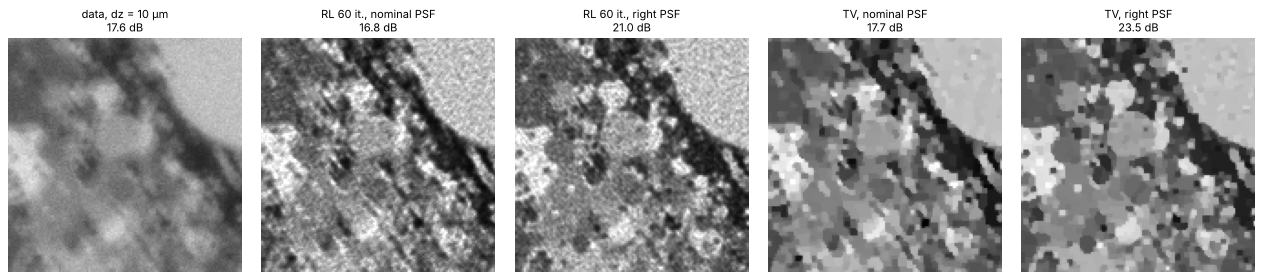

In [21]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.4))
lab = CASES[-2][0]
pics = [("data, " + lab, mis[lab][0]), ("RL 60 it., nominal PSF", mis[lab][1]["RL, 60 it."]),
        ("RL 60 it., right PSF", mis[lab][2]["RL, 60 it."]), ("TV, nominal PSF", mis[lab][1]["TV"]),
        ("TV, right PSF", mis[lab][2]["TV"])]
for a, (name, img) in zip(axes, pics):
    a.imshow(img[60:188, 60:188], cmap="gray", vmin=0, vmax=1, origin="lower")
    a.set_title("{}\n{:.1f} dB".format(name, rs.psnr(img, truth1, border=B)), fontsize=10)
    a.axis("off")
fig.tight_layout()

With the wrong PSF, Richardson–Lucy produces halos and noisy texture
along the edges, and TV breaks the discs into wrong facets.

## 8. Learned: an unrolled solver with six parameters per step

The learned methods of section 0 replace the hand tuned parts of an
iterative solver by trained ones and fix the number of iterations. The
simplest such "network" is half-quadratic splitting with $K$ steps
(`rs.unrolled_hqs()`): each step solves the data problem
$\min_x |h * x - y|^2 + \rho_k |x - z|^2$ exactly by FFT and then denoises,
$z = $ soft thresholding of the Haar wavelet coefficients of $x$ with a
threshold $t_k$. The $2K$ numbers $(\rho_k, t_k)$ are the weights; they are
learned by minimizing the mean square error on six training images of
160 × 160 pixels (blurred with the 0.7 field PSF and with noise), with a
derivative free optimizer. A real network would learn a CNN denoiser with
millions of weights and back-propagation, and would take the PSF as an
input; the structure is the same.

In [22]:
def pair(seed, n=160, m=16):
    x = rs.dead_leaves((n + 2*m, n + 2*m), r_min=1.5, r_max=80, rng=seed)
    y = expose(rs.SpaceVariantBlur.invariant(psf07, (n, n), margin=m).forward(x), seed + 1000)
    return x[m:-m, m:-m], y


train = [pair(s) for s in range(100, 106)]
STEPS = 6


def loss(p, data):
    P = p.reshape(-1, 2)
    return np.mean([np.mean((rs.unrolled_hqs(y, psf07, P) - x)[8:-8, 8:-8]**2) for x, y in data])


p0 = np.column_stack([np.linspace(-1.5, -3.0, STEPS), np.full(STEPS, -1.5)]).ravel()
t0 = time.time()
fit = minimize(loss, p0, args=(train,), method="Powell", bounds=[(-5, 1), (-4, -0.5)]*STEPS,
               options=dict(maxiter=4, xtol=1e-2, ftol=1e-4))
params = fit.x.reshape(-1, 2)
print("training: {} evaluations in {:.0f} s; loss {:.2e} -> {:.2e}".format(fit.nfev, time.time() - t0,
                                                                         loss(p0, train), fit.fun))
print("step   rho_k       t_k")
for k, (a, b) in enumerate(params):
    print("{:3d}   {:8.2e}   {:8.2e}".format(k + 1, 10**a, 10**b))

training: 560 evaluations in 91 s; loss 1.56e-01 -> 6.89e-03
step   rho_k       t_k
  1   2.13e-02   2.11e-02
  2   4.66e-02   3.79e-02
  3   4.25e-02   2.34e-02
  4   4.61e-02   8.00e-02
  5   4.48e-02   9.89e-02
  6   3.20e-02   1.55e-02


The learned schedule is easy to read. The coupling $\rho_k$ starts at
0.02 and stays around 0.04 to 0.05. The thresholds are small in the
first three steps (0.02 to 0.04), which act almost as Wiener filters,
rise to 0.08–0.10 in steps 4 and 5, which remove the amplified noise, and
drop to 0.016 in the last step, which keeps the detail at the end. This
is the continuation that one would otherwise tune by hand.

In [23]:
t0 = time.time()
x_hqs = rs.unrolled_hqs(y1, psf07, params)
t_hqs = time.time() - t0
t0 = time.time()
rs.deconvolve_tv(y1, op07c, LAM_TV, n_iter=200)
t_tv = time.time() - t0
print("test image of section 4 ({} x {} pixels, not in the training set):".format(N1, N1))
print("  data                       {:.2f} dB".format(rs.psnr(y1, truth1, border=B)))
print("  Wiener, spectral NSR       {:.2f} dB".format(p_wien_model))
print("  Richardson-Lucy (best)     {:.2f} dB".format(max(p_rl)))
print("  TV (best λ)                {:.2f} dB   {:.2f} s".format(max(p_tv), t_tv))
print("  unrolled HQS, {} steps      {:.2f} dB   {:.2f} s".format(STEPS, rs.psnr(x_hqs, truth1, border=B), t_hqs))

test image of section 4 (256 x 256 pixels, not in the training set):
  data                       18.54 dB
  Wiener, spectral NSR       22.59 dB
  Richardson-Lucy (best)     22.28 dB
  TV (best λ)                23.54 dB   0.86 s
  unrolled HQS, 6 steps      22.82 dB   0.07 s


On the test image the six step network reaches 22.8 dB, above
Richardson–Lucy (22.3 dB) and the spectral Wiener filter (22.6 dB) and
0.7 dB below TV (23.5 dB), and it runs in 0.07 s instead of 0.9 s for
TV. That speed, from a fixed small number of steps, is the main practical
argument for unrolling. With a fixed Haar threshold as its "prior" it
cannot beat TV on a scene made of flat discs. With learned CNN
denoisers, the unrolled and plug-and-play methods of section 0 beat the
hand-made priors on natural images in their benchmarks, and they take
the PSF as an input (Li et al. 2021; MultiWienerNet) to handle the field.

All of them are trained on pairs made with a forward model like the one
built here: channel PSFs over the field, the mosaic and the noise. The
PSF atlas of the lens is the asset, and the network is what is trained on
it.

## Summary

- **The forward model is the core.** For this f/1.8 phone lens the
  channel PSFs must be spectral sums over the band (one design line per
  channel is 9–36 % off in the field), include the lateral colour as a
  smear rather than a shift, and depend mildly on the light (up to 8 %
  for a 3000 K lamp).
- **The PSF changes fast over the field.** In the corner neighbouring
  nodes 128 pixels apart differ by up to half the norm of the PSF; four
  eigen-PSFs leave 14–18 % of the error. One PSF for a 512 pixel tile
  gains 2.5 dB but unevenly, with the wrong kernel where the PSF differs.
- **Space variant solvers work.** TV on eigen-PSFs gains 4.1 dB in the
  corner, Richardson–Lucy on interpolated PSFs and the blended Wiener
  filter 3.4–3.5 dB; a denser PSF grid adds only 0.1 dB. At 0.7 field one
  PSF holds over 256 pixels, and the gain is 4.1 to 5.0 dB (spectral
  Wiener, TV).
- **Regularization is everything.** The inverse filter is useless, the
  spectral Wiener filter needs no tuning, Richardson–Lucy has to be
  stopped, and TV wins on flat scenes. Above about 0.35 cycles per pixel
  nothing comes back at 1000 photo electrons.
- **Colour noise is the price.** Deconvolving the channels independently
  after demosaicing raises the chroma error by 15 %. Joint restoration on
  the Bayer mosaic with the cross-channel prior brings it below that of
  the unrestored image, at a cost in PSNR.
- **Systematic PSF errors dominate.** Noise in a measured PSF hardly
  matters, but 10 µm of defocus costs 4–6 dB, and the infinity PSF
  applied to a refocused close-up makes the image worse than no
  restoration at all.
- **Learned methods are fast regularized solvers trained on this kind of
  model.** Six unrolled steps with 12 learned numbers come within 0.7 dB
  of TV at 12 times the speed. The state of the art adds CNN or
  diffusion priors, PSF maps as inputs, and pre-training on libraries of
  lenses.

## References

- N. Wiener, *Extrapolation, interpolation, and smoothing of stationary
  time series*, MIT Press (1949).
- W. H. Richardson, "Bayesian-based iterative method of image restoration",
  J. Opt. Soc. Am. 62, 55 (1972); L. B. Lucy, "An iterative technique for
  the rectification of observed distributions", Astron. J. 79, 745 (1974);
  L. A. Shepp and Y. Vardi, "Maximum likelihood reconstruction for emission
  tomography", IEEE Trans. Med. Imaging 1, 113 (1982).
- L. I. Rudin, S. Osher and E. Fatemi, "Nonlinear total variation based
  noise removal algorithms", Physica D 60, 259 (1992).
- D. Geman and C. Yang, "Nonlinear image recovery with half-quadratic
  regularization", IEEE Trans. Image Process. 4, 932 (1995).
- A. Levin, R. Fergus, F. Durand and W. T. Freeman, "Image and depth from a
  conventional camera with a coded aperture", ACM Trans. Graph. 26, 70
  (2007); D. Krishnan and R. Fergus, "Fast image deconvolution using
  hyper-Laplacian priors", NIPS (2009).
- S. Boyd, N. Parikh, E. Chu, B. Peleato and J. Eckstein, "Distributed
  optimization and statistical learning via the alternating direction
  method of multipliers", Found. Trends Mach. Learn. 3, 1 (2011);
  A. Chambolle and T. Pock, "A first-order primal-dual algorithm for convex
  problems with applications to imaging", J. Math. Imaging Vis. 40, 120
  (2011); L. Condat, J. Optim. Theory Appl. 158, 460 (2013); B. C. Vu,
  Adv. Comput. Math. 38, 667 (2013).
- J. G. Nagy and D. P. O'Leary, "Restoring images degraded by spatially
  variant blur", SIAM J. Sci. Comput. 19, 1063 (1998).
- D. Flicker and F. Rigaut, "Anisoplanatic deconvolution of adaptive optics
  images", J. Opt. Soc. Am. A 22, 504 (2005).
- L. Denis, E. Thiébaut, F. Soulez, J.-M. Becker and R. Mourya, "Fast
  approximations of shift-variant blur", Int. J. Comput. Vis. 115, 253
  (2015).
- M. Hirsch, S. Sra, B. Schölkopf and S. Harmeling, "Efficient filter flow
  for space-variant multiframe blind deconvolution", CVPR (2010).
- E. Kee, S. Paris, S. Chen and J. Wang, "Modeling and removing
  spatially-varying optical blur", ICCP (2011).
- C. J. Schuler, M. Hirsch, S. Harmeling and B. Schölkopf, "Non-stationary
  correction of optical aberrations", ICCV (2011); "Blind correction of
  optical aberrations", ECCV (2012).
- N. Joshi, R. Szeliski and D. J. Kriegman, "PSF estimation using sharp edge
  prediction", CVPR (2008); M. Delbracio, P. Musé, A. Almansa and
  J.-M. Morel, "The non-parametric sub-pixel local point spread function
  estimation is a well posed problem", Int. J. Comput. Vis. 96, 175 (2012);
  A. Mosleh, P. Green, E. Onzon, I. Begin and J. M. P. Langlois, "Camera
  intrinsic blur kernel estimation: a reliable framework", CVPR (2015).
- F. Heide, M. Rouf, M. B. Hullin, B. Labitzke, W. Heidrich and A. Kolb,
  "High-quality computational imaging through simple lenses", ACM Trans.
  Graph. 32, 149 (2013); F. Heide et al., "FlexISP: a flexible camera image
  processing framework", ACM Trans. Graph. 33, 231 (2014).
- C. J. Schuler, H. C. Burger, S. Harmeling and B. Schölkopf, "A machine
  learning approach for non-blind image deconvolution", CVPR (2013);
  L. Xu, J. S. J. Ren, C. Liu and J. Jia, "Deep convolutional neural network
  for image deconvolution", NIPS (2014).
- K. Zhang, W. Zuo, S. Gu and L. Zhang, "Learning deep CNN denoiser prior for
  image restoration", CVPR (2017); K. Zhang, Y. Li, W. Zuo, L. Zhang, L. Van
  Gool and R. Timofte, "Plug-and-play image restoration with deep denoiser
  prior", IEEE Trans. Pattern Anal. Mach. Intell. 44, 6360 (2022, online
  2021); K. Zhang, L. Van Gool and R. Timofte, "Deep unfolding network for
  image super-resolution", CVPR (2020).
- J. Dong, S. Roth and B. Schiele, "Deep Wiener deconvolution: Wiener meets
  deep learning for image deblurring", NeurIPS (2020).
- K. Yanny, K. Monakhova, R. W. Shuai and L. Waller, "Deep learning for fast
  spatially varying deconvolution", Optica 9, 96 (2022).
- S. Chen, H. Feng, D. Pan, Z. Xu, Q. Li and Y. Chen, "Optical aberrations
  correction in postprocessing using imaging simulation", ACM Trans. Graph.
  40(5) (2021).
- X. Li, J. Suo, W. Zhang, X. Yuan and Q. Dai, "Universal and flexible
  optical aberration correction using deep-prior based deconvolution",
  ICCV (2021).
- J. Gong et al., "A physics-informed low-rank deep neural network for blind
  and universal lens aberration correction", CVPR (2024).
- X. Qian et al., "Towards blind lens aberration correction via large LensLib
  pre-training and discrete degradation priors", arXiv:2511.17126 (2025);
  X. Qian et al., "LensBridge: frequency-guided compound degradation
  adaptation for lens aberration correction and veiling glare removal",
  arXiv:2610.00318 (2026); H. Weligampola, Y. Chen, W. Tang, Q. Guo and
  S. H. Chan, "Diffusion algorithm for metalens optical aberration
  correction", arXiv:2511.12689 (2025).
- V. Sitzmann et al., "End-to-end optimization of optics and image
  processing for achromatic extended depth of field and super-resolution
  imaging", ACM Trans. Graph. 37, 114 (2018); E. Tseng et al.,
  "Differentiable compound optics and processing pipeline optimization for
  end-to-end camera design", ACM Trans. Graph. 40, 18 (2021).
- S. W. Hasinoff et al., "Burst photography for high dynamic range and
  low-light imaging on mobile cameras", ACM Trans. Graph. 35, 192 (2016);
  B. Wronski et al., "Handheld multi-frame super-resolution", ACM Trans.
  Graph. 38, 28 (2019).
- M. Delbracio, I. Garcia-Dorado, S. Choi, D. Kelly and P. Milanfar,
  "Polyblur: removing mild blur by polynomial reblurring", IEEE Trans.
  Comput. Imaging 7 (2021); M. Delbracio, D. Kelly, M. S. Brown and
  P. Milanfar, "Mobile computational photography: a tour", Annu. Rev. Vis.
  Sci. 7, 571 (2021).
- Android `CaptureRequest` documentation (shading, aberration, distortion,
  noise reduction and edge modes), developer.android.com.
- ISO 19567-2:2019, "Photography — Digital cameras — Part 2: Texture
  analysis using stochastic pattern".

In [24]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 513 s
